c:\Users\raoaf\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.6300 - loss: 1.1200
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7975 - loss: 0.5636
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.8037 - loss: 0.5044
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8544 - loss: 0.4073
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8813 - loss: 0.3559
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.8888 - loss: 0.3179
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.8863 - loss: 0.3104
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9081 - loss: 0.2742
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.9112 - loss: 0.2574
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9187 - loss: 0.2481
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9137 - loss: 0.2396
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 12, 12, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 4, 4, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,390 (677.31 KB)

 Trainable params: 57,796 (225.77 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 115,594 (451.54 KB)

None
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9625 - loss: 0.3693
Loss:  0.3693382740020752
Accuracy:  0.9624999761581421


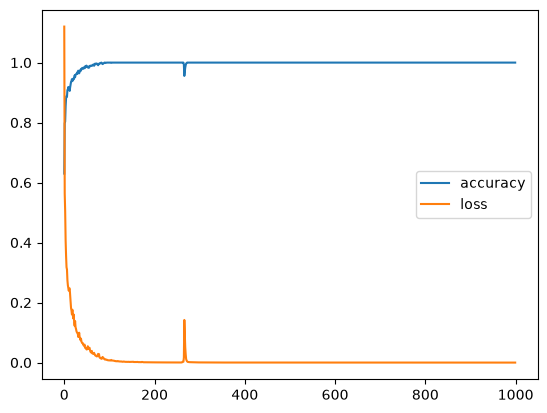

In [2]:

import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, AveragePooling2D, Flatten, Conv2D
from keras.utils import to_categorical


csv_path = r'C:\My Files\ANN & ML Projects\ANNDL_Fall_2026\Project_ANNDL_Fall_2026\data\processed\Images28.csv'
data = pd.read_csv(csv_path, header=None)

Y = data.iloc[:, 0].values
X = data.iloc[:, 1:].values
X = X.reshape(-1, 28, 28, 3)
X = X.astype('float32') / 255.0

Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=42)

num_classes = 4
Ytrain = to_categorical(Ytrain, num_classes)
Ytest = to_categorical(Ytest, num_classes)

cnn = Sequential()
cnn.add(Conv2D(32, (5, 5), activation='relu', input_shape=(28, 28, 3)))
cnn.add(AveragePooling2D(pool_size=(2, 2)))
cnn.add(Conv2D(filters=64, kernel_size=(5, 5), activation='relu', padding='valid', strides=(1, 1)))
cnn.add(AveragePooling2D(2, 2))
cnn.add(Flatten())
cnn.add(Dense(4, activation='softmax'))

cnn.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

result = cnn.fit(Xtrain, Ytrain, epochs=1000, batch_size=128, verbose=1)
print(cnn.summary())
loss,acc = cnn.evaluate(Xtest,Ytest)
print("Loss: ", loss)
print("Accuracy: ",acc)
pd.DataFrame(result.history).plot()
plt.show()
cnn.save('C:\\My Files\\ANN & ML Projects\\ANNDL_Fall_2026\\Project_ANNDL_Fall_2026\\models\\images28_avg_cnn_model.keras')



In [3]:
model1 = tf.keras.models.load_model(r"C:\My Files\ANN & ML Projects\ANNDL_Fall_2026\Project_ANNDL_Fall_2026\models\images28_avg_cnn_model.keras")
image = cv2.imread(r"C:\My Files\ANN & ML Projects\ANNDL_Fall_2026\Project_ANNDL_Fall_2026\data\sample\sneaker.jpeg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image1 = cv2.resize(image, (28, 28))
image1 = image1.astype("float32") / 255.0
test_img = image1.reshape(1, 28, 28, 3)
#test_img = np.expand_dims(test_img, axis=0)
p = model1.predict(test_img)
labels = {0: "Boot", 1: "Sandal", 2: "Shoe", 3: "Sneaker"}
ind = np.argmax(p)
print(labels[ind])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
Sandal
